# Forgemaster Steam Reviews v1 데이터 분석

2026-11-08. 원본 11개 파일 전체를 분석한 결과. 실제 학습/정답 분할 및 추천 지표 평가는 수행하지 않았습니다.

전체 설명: [보고서](../reports/forgemaster_eda.md). 재수집·전수 집계 명령은 보고서 마지막을 참조하세요.

**후속 모델 평가 완료:** Kieran 원본을 복원하고 평가 계정을 학습에서 제외해 다시 학습했다. 결과는 [모델 평가 보고서](../reports/forgemaster_model_evaluation.md)에서 확인할 수 있다. 이 문서의 모델 파일 부재와 학습·평가 계정 중복 미검사는 그 이전 EDA 단계의 상태다.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Markdown, Image
EDA = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd() / 'EDA'
m = json.loads((EDA / 'reports/forgemaster_eda_metrics.json').read_text('utf-8'))
T = EDA / 'reports/tables/forgemaster'
display(pd.DataFrame([m['raw'],m['clean']],index=['raw','clean']))

,rows,users,apps,positives,positive_rate
raw,15437471,6976390,8183,NaN,NaN
clean,15436770,6976389,8183,13423711.0,0.869593


## 열별 품질 검사

SteamID는 문자열로 보존합니다. 라벨 충돌 사용자–게임은 전체 제외하고 동일 라벨 반복은 한 쌍으로 합쳤습니다. 두 파서의 파일별 전체 행 수를 대조했습니다.

In [2]:
display(pd.read_csv(T / '02_schema_quality.csv'))
display(pd.Series(m['duplicates'],name='사용자–게임 중복 검사'))
display(pd.Series(m['quality'],name='품질 검사 결과'))
display(pd.Series(m['additional_saved_output_audit']['timestamps'],name='날짜 검사 결과'))
display(pd.Series(m['reconciliation'],name='집계 일치 검사'))

,column,null_or_blank,invalid_cast
0,steamid,0,0
1,appid,0,0
2,voted_up,0,0
3,votes_up,0,0
4,votes_funny,0,0
5,weighted_vote_score,0,0
6,playtime_forever,0,0
7,playtime_at_review,0,0
8,num_games_owned,0,0
9,num_reviews,0,0


distinct_pairs               15436778
extra_user_game_rows              693
repeated_pairs                    395
conflicting_pairs                   8
rows_in_conflicting_pairs          22
Name: 사용자–게임 중복 검사, dtype: int64

invalid_steamid_rows                       0
invalid_appid_rows                         0
missing_label_rows                         0
negative_playtime_rows                     0
playtime_at_review_gt_forever           7155
updated_before_created                     0
created_outside_publish_window             0
negative_user_metadata                     0
negative_votes                             0
invalid_helpfulness_score                  0
non_ascii_text_rows                   437139
first_created_unix                1287181669
last_created_unix                 1619152533
first_updated_unix                1287185111
last_updated_unix                 2285482808
Name: 품질 검사 결과, dtype: int64

updated_after_publication_rows                              1
updated_after_analysis_date_rows                            1
negative_updated_timestamp_rows                             0
first_created_utc                   2010-10-15T22:27:49+00:00
last_created_utc                    2021-04-23T04:35:33+00:00
first_updated_utc                   2010-10-15T23:25:11+00:00
last_updated_utc                    2042-06-04T08:20:08+00:00
Name: 날짜 검사 결과, dtype: object

source_rows_match_publisher     True
source_users_match_publisher    True
source_apps_match_publisher     True
file_row_sum_matches            True
python_csv_total_matches        True
python_csv_each_file_matches    True
game_pair_sum_matches           True
user_pair_sum_matches           True
years_sum_matches               True
cap_row_counts_match            True
clean_pair_uniqueness           True
clean_labels_unambiguous        True
Name: 집계 일치 검사, dtype: bool

## 게임·사용자·시간 분포

,minimum,maximum,mean,quantiles
per game,1,976130,1886.443847,"[67, 179, 638, 2598, 6086, 28556]"
per user,1,840,2.212716,"[1, 1, 2, 4, 6, 16]"


,app_id,reviews,positives,positive_rate,title,in_input_catalog,in_linux_candidates
0,730,976130,858958.0,0.879963,Counter-Strike: Global Offensive,True,True
1,359550,338197,304875.0,0.901472,Tom Clancy's Rainbow Six® Siege,True,False
2,105600,322227,316254.0,0.981463,Terraria,True,True
3,4000,297044,287346.0,0.967352,Garry's Mod,True,True
4,271590,294087,224038.0,0.761809,Grand Theft Auto V,True,False
5,252490,251886,220840.0,0.876746,Rust,True,False
6,578080,245674,150619.0,0.613085,PUBG: BATTLEGROUNDS,True,False
7,252950,193048,172899.0,0.895627,NaN,NaN,False
8,413150,157864,156107.0,0.988870,Stardew Valley,True,True
9,346110,154335,118690.0,0.769041,ARK: Survival Evolved,True,False


,year,reviews,positive_rate
0,2010,10790,0.980816
1,2011,66646,0.968775
2,2012,87455,0.965617
3,2013,284983,0.930512
4,2014,978346,0.877613
5,2015,1281813,0.841372
6,2016,1699640,0.840164
7,2017,1937378,0.808694
8,2018,1701601,0.801934
9,2019,2477434,0.894107


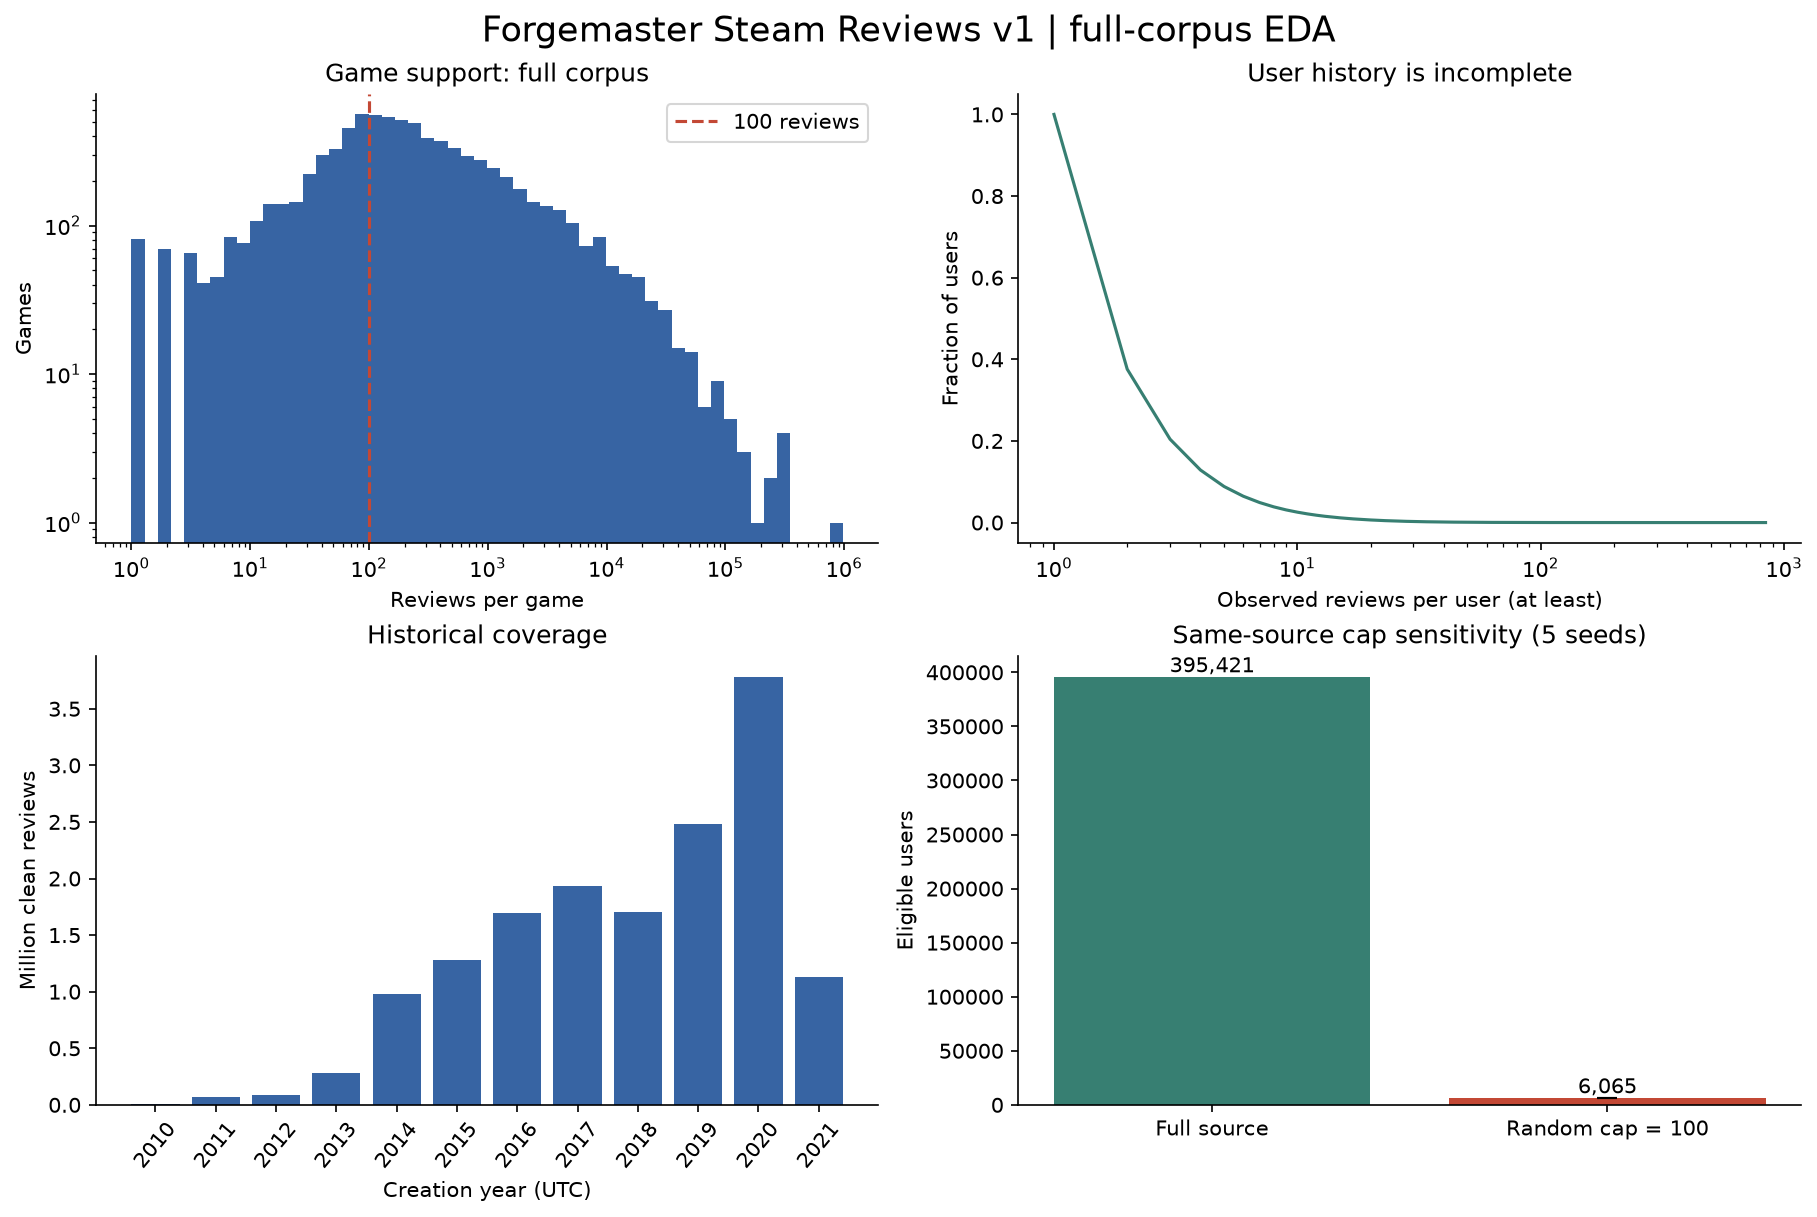

In [3]:
display(pd.DataFrame([m['reviews_per_game'],m['reviews_per_user']],index=['per game','per user']))
display(pd.read_csv(T / '03_game_support.csv').head(20))
display(pd.read_csv(T / '06_review_years.csv'))
display(Image(filename=str(EDA / 'figures/forgemaster/01_overview.png')))

## 입력·추천 게임 목록과 평가 가능 사용자

정답 한 개를 숨긴 뒤 최소 전체 입력 5개·긍정 입력 1개가 기본 조건입니다. 아래는 EDA 단계에서 계산한 평가 가능 사용자 수입니다.

In [4]:
display(pd.Series(m['catalog_coverage'],name='게임 목록의 데이터 포함 범위'))
display(pd.read_csv(T / '07_evaluation_eligibility.csv'))
display(pd.Series(m['full_eligible_history'],name='평가 대상자의 리뷰 이력'))

source_apps                     8183
input_apps_covered              7460
linux_candidates_covered        2210
rows_in_input_catalog       14800111
positive_linux_rows          5673791
total_input_apps               37610
total_linux_candidates          6630
Name: 게임 목록의 데이터 포함 범위, dtype: int64

,minimum_inputs_after_holdout,potential_users,eligible_users,possible_target_pairs
0,1,1808495,1715810,3744836
1,3,745862,741465,2367624
2,5,396238,395421,1679068
3,10,135440,135381,920815


users                          3.954210e+05
mean_inputs_after_holdout      1.061666e+01
median_inputs_after_holdout    7.000000e+00
possible_target_pairs          1.679068e+06
Name: 평가 대상자의 리뷰 이력, dtype: float64

## 게임당 최대 100개 제한: 난수 시드 5개

균등 무작위 제한은 frank의 실제 API 정렬·선별을 복원하지 않습니다. 게임별 긍정률 MAE는 추천 성능 지표가 아닙니다.

,seed,rows,apps,positives,positive_rate,mean_inputs_after_holdout,median_inputs_after_holdout,possible_target_pairs,all_sample_users,eligible_users,full_history_mean_inputs_for_same_cap_eligible_users,full_top10_review_share_after_cap,mean_absolute_error,median_absolute_error,p90_absolute_error,games
0,20261108,660671,8183,511698,0.774513,10.958238,7.0,20488,462812,6130,51.773736,0.001514,0.022741,0.017246,0.049234,5288
1,20261109,660671,8183,511001,0.773458,10.946222,7.0,20413,463529,6062,51.853019,0.001514,0.022923,0.017665,0.049814,5288
2,20261110,660671,8183,511192,0.773747,11.023989,8.0,20414,462940,6086,52.197502,0.001514,0.022547,0.017457,0.049059,5288
3,20261111,660671,8183,511177,0.773724,11.029620,7.0,20342,462511,6077,51.974165,0.001514,0.022251,0.017300,0.048888,5288
4,20261112,660671,8183,511257,0.773845,11.044061,7.0,20209,463241,5969,51.920925,0.001514,0.022601,0.017625,0.048930,5288


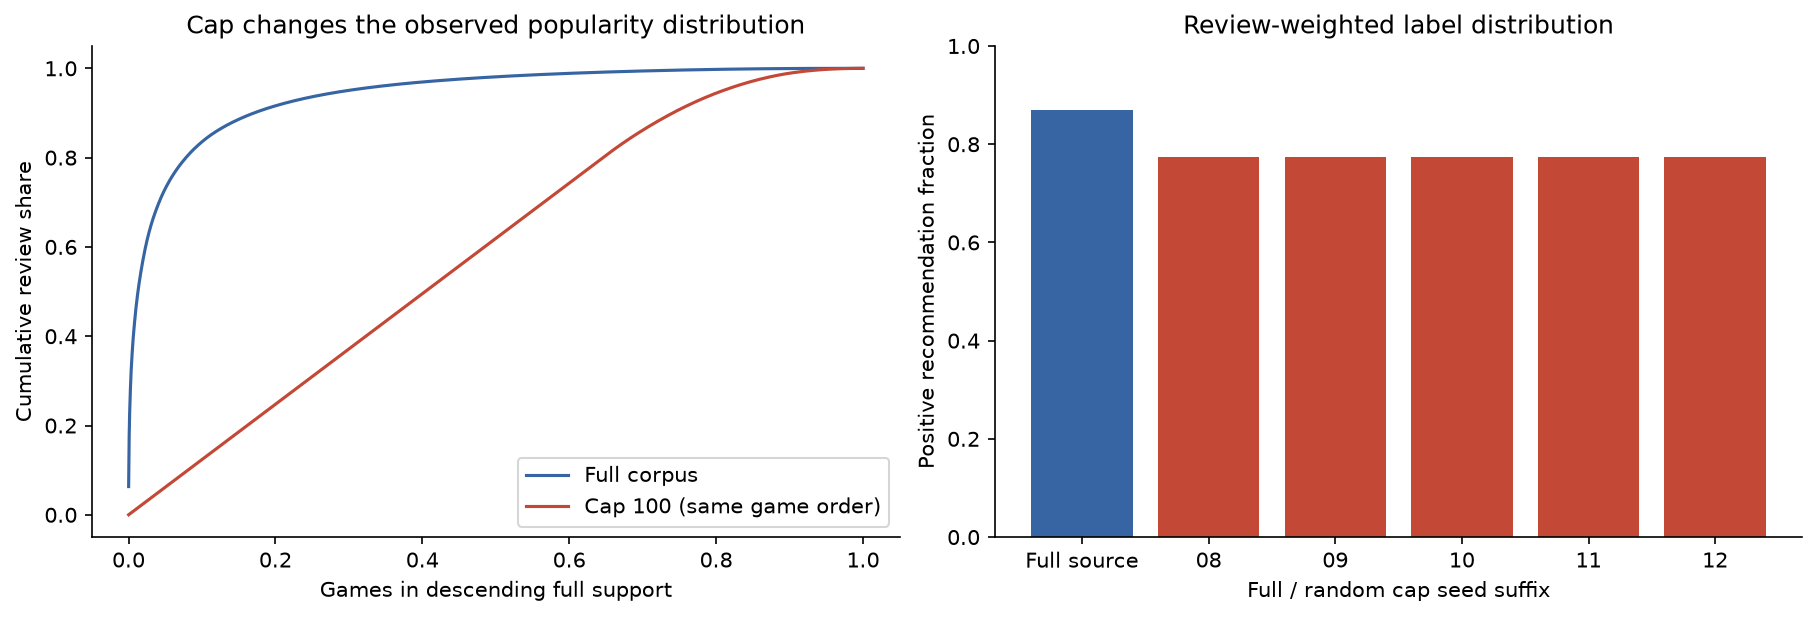

In [5]:
display(pd.read_csv(T / '09_cap_sensitivity.csv'))
display(Image(filename=str(EDA / 'figures/forgemaster/02_cap_distribution.png')))

## frank 중복과 학습·평가 계정 중복 검사

정확한 SteamID와 App ID를 대조했습니다. 이 EDA 당시에는 Kieran 계정별 분할 파일이 없어 학습·평가 계정 중복을 확인하지 못했습니다. 후속 모델 평가에서는 계정을 분리했습니다.

In [6]:
display(pd.Series(m['frank_comparison']['overlap'],name='계정·게임 ID 중복'))
display(pd.Series(m['frank_comparison']['source_eligible_overlap'],name='평가 가능 사용자 중복'))
display(pd.Series(m['training_identity_audit']))

shared_users                       594342
shared_user_game_pairs             149113
shared_pair_label_disagreements      3629
shared_games                         7873
Name: 계정·게임 ID 중복, dtype: int64

source_eligible_users_with_frank_catalog_history    125754
eligible_in_both                                     13016
source_eligible_users_in_any_frank                  148210
Name: 평가 가능 사용자 중복, dtype: int64

status                                              NOT_VERIFIED
reason         The recorded Kieran and split_v1 identity arti...
consequence    Do not evaluate the existing trained models as...
dtype: str

## 결론

100개 제한의 분포·이력 영향을 살피는 **리뷰 수 제한의 영향을 확인하는 추가 평가 데이터**입니다. 모델 평가에는 Kieran 학습 계정과 중복되지 않게 분리한 데이터를 사용합니다. 2021년 자료·일부 게임만 포함하므로 최신 게임 및 전체 후보의 성능을 대표하지 않습니다.